# Summary for Serie A Webapp

# 1. Scraping Fixtures

# 2. Scraping Players

# 3. Creation of a joint Dataset

# 4. Data Exploration and Visualization

# 5. Model Training

## Auto ML

In [184]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
import h2o
from h2o.automl import H2OAutoML

In [185]:
df_pandas = pd.read_excel("trainable_dataset.xlsx", engine='openpyxl', dtype={'Risultato': str})
df_pandas['Risultato'] = df_pandas['Risultato'].replace('X', '3')

In [186]:
print(df_pandas.head())

  Risultato  Ball possession_Casa  Expected goals (xG)_Casa  \
0         2                    47                      0.70   
1         2                    48                      0.89   
2         2                    32                      0.21   
3         1                    48                      2.69   
4         3                    60                      1.90   

   Expected goals (xG)_Fuori  Accurate passes_Casa  Accurate passes_Fuori  \
0                       0.51                    64                     71   
1                       1.50                    88                     89   
2                       0.99                    75                     88   
3                       0.78                    90                     90   
4                       0.14                    82                     73   

   Shots inside box_Casa  Shots inside box_Fuori  Shots outside box_Casa  \
0                      4                       6                       6   
1     

In [ ]:
h2o.init()
# togliamo eventuali spazi vuoti nei nomi
df_pandas.columns = df_pandas.columns.str.strip()
df = h2o.H2OFrame(df_pandas)

target = 'Risultato'

# as factor categorizza la variabile 
df[target] = df[target].asfactor()

ignore_columns = ['Home_ID', 'Away_ID', target]
predictors = [col for col in df.columns if col not in ignore_columns]

# Suddivisione dei dati in Train (80%) e Test (20%)
train, test = df.split_frame(ratios=[0.8], seed=42)

# inizializza e avvia H2O AutoML
print("Inizio l'addestramento con H2O AutoML...")
# massimo di 20 modelli base 
aml = H2OAutoML(max_models=20, seed=42, sort_metric="mean_per_class_error") 

# Avvia l'addestramento
aml.train(x=predictors, y=target, training_frame=train)

Checking whether there is an H2O instance running at http://localhost:54321. connected.


H2O_cluster_uptime:,4 hours 54 mins
H2O_cluster_timezone:,Europe/Rome
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.11
H2O_cluster_version_age:,1 month
H2O_cluster_name:,H2O_from_python_Giacomo_6lfce4
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,3.390 Gb
H2O_cluster_total_cores:,12
H2O_cluster_allowed_cores:,12
H2O_cluster_status:,"locked, healthy"


Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Inizio l'addestramento con H2O AutoML...
AutoML progress: |█
16:17:38.340: AutoML: XGBoost is not available; skipping it.

██████████████████████████████████████████████████████████████| (done) 100%


key,value
Stacking strategy,cross_validation
Number of base models (used / total),15/20
# GBM base models (used / total),6/10
# DeepLearning base models (used / total),6/7
# GLM base models (used / total),1/1
# DRF base models (used / total),2/2
Metalearner algorithm,GLM
Metalearner fold assignment scheme,Random
Metalearner nfolds,5
Metalearner fold_column,None


In [188]:
print("\n--- LEADERBOARD DEI MODELLI ---")
lb = aml.leaderboard

print(lb.head(rows=lb.nrows))


--- LEADERBOARD DEI MODELLI ---
model_id                                                   mean_per_class_error    logloss      rmse       mse
StackedEnsemble_AllModels_1_AutoML_2_20260622_161738                   0.358185   0.746035  0.515597  0.26584
StackedEnsemble_BestOfFamily_1_AutoML_2_20260622_161738                0.361077   0.748879  0.517469  0.267774
DeepLearning_grid_3_AutoML_2_20260622_161738_model_2                   0.366403   0.799615  0.521981  0.272464
GBM_5_AutoML_2_20260622_161738                                         0.371816   0.795604  0.528761  0.279589
GBM_grid_1_AutoML_2_20260622_161738_model_4                            0.374675   0.804527  0.535058  0.286287
DeepLearning_grid_2_AutoML_2_20260622_161738_model_2                   0.377363   0.839893  0.522255  0.27275
GBM_2_AutoML_2_20260622_161738                                         0.378216   0.784021  0.526126  0.276809
GBM_4_AutoML_2_20260622_161738                                         0.380441  

In [189]:
# metriche del modello vincitore sul Test Set
best_model = aml.leader
print("\nIl modello migliore (Leader) trovato da H2O AutoML è un:", best_model.algo)

print("\n--- PERFORMANCE DEL MODELLO VINCITORE SUL TEST SET ---")
performance = best_model.model_performance(test)
print(performance)


Il modello migliore (Leader) trovato da H2O AutoML è un: stackedensemble

--- PERFORMANCE DEL MODELLO VINCITORE SUL TEST SET ---
ModelMetricsMultinomialGLM: stackedensemble
** Reported on test data. **

MSE: 0.29016845137499764
RMSE: 0.5386728611829239
LogLoss: 0.8551137292154347
Null degrees of freedom: 234
Residual degrees of freedom: 198
Null deviance: 507.3270311783366
Residual deviance: 401.90345273125433
AUC table was not computed: it is either disabled (model parameter 'auc_type' was set to AUTO or NONE) or the domain size exceeds the limit (maximum is 50 domains).
AUCPR table was not computed: it is either disabled (model parameter 'auc_type' was set to AUTO or NONE) or the domain size exceeds the limit (maximum is 50 domains).

Confusion Matrix: Row labels: Actual class; Column labels: Predicted class
1    2    3    Error     Rate
---  ---  ---  --------  --------
81   4    17   0.205882  21 / 102
9    45   16   0.357143  25 / 70
26   12   25   0.603175  38 / 63
116  61   58 

### AutoML Results
- Errori Vittoria in casa: 20 errori / 102 guesses
- Errori Vittoria fuori casa: 25 errori / 70 guesses
- Errori Pareggio: 40 errori / 63 guesses
- Errori Totali: 85 errori / 235 guesses --> circa 36%
- Accuracy del modello Stacked Ensemble --> circa 64%

## Logistic Regression
Is the classic model used with sport datasets because it can also give the probability of win, draw and loss as a percentage

- Need to standardize and scale the data in order to make it work properly

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

### Load and Prepare Data

#### Load and Split

In [2]:

df = pd.read_excel("trainable_dataset.xlsx", engine='openpyxl', dtype={'Risultato': str})
df['Risultato'] = df['Risultato'].replace('X', '3')
df.columns = df.columns.str.strip()


X = df.drop(columns=['Risultato', 'Home_ID', 'Away_ID']).fillna(0)
y = df['Risultato']



# stratify=y garantisce la stessa proporzione di valori target nei due set
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

#### Standardize Data

In [3]:
# Scaliamo sia test che train
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Train Logistic Regression

In [4]:

print("Addestramento della Regressione Logistica in corso...")

log_reg = LogisticRegression(solver='lbfgs', max_iter=1000, random_state=42) # dovrebbe capire da solo che è multiclass
log_reg.fit(X_train_scaled, y_train)


y_pred = log_reg.predict(X_test_scaled)

Addestramento della Regressione Logistica in corso...


### Logistic Regression Results

In [194]:
accuracy = accuracy_score(y_test, y_pred)
print(f"\n--- LOGISTIC REGRESSION RESULTS ---")
print(f"Test Set Accuracy: {accuracy * 100:.2f}%\n")

print("Detailed Report:")
print(classification_report(y_test, y_pred))


--- LOGISTIC REGRESSION RESULTS ---
Test Set Accuracy: 64.47%

Detailed Report:
              precision    recall  f1-score   support

           1       0.68      0.81      0.74        91
           2       0.70      0.78      0.74        73
           3       0.43      0.25      0.32        64

    accuracy                           0.64       228
   macro avg       0.60      0.61      0.60       228
weighted avg       0.61      0.64      0.62       228



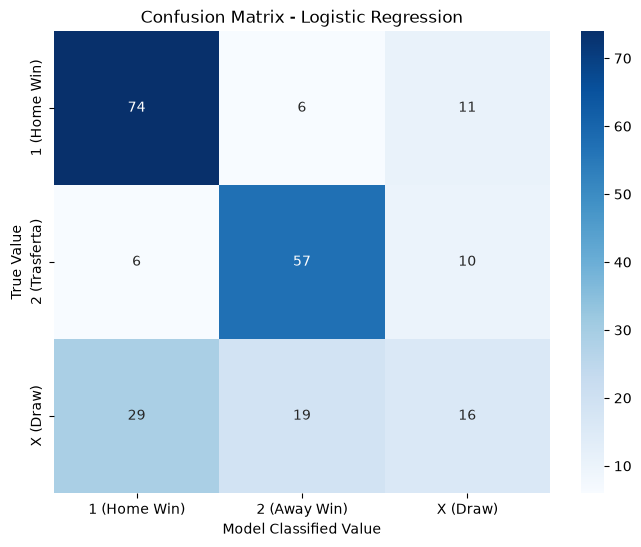

In [195]:
cm = confusion_matrix(y_test, y_pred, labels=['1', '2', '3'])
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['1 (Home Win)', '2 (Away Win)', 'X (Draw)'], 
            yticklabels=['1 (Home Win)', '2 (Trasferta)', 'X (Draw)'])
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Model Classified Value')
plt.ylabel('True Value')
plt.show()

The model is very good in predicting <b>Home Wins (74/91 = 81% accu)</b> or <b>Away Wins (57/73 = 78% accu)</b>, but it behaves worst than random when classifying Draws <b>(16/64 = 25% accu)</b><br>
Even with a terrible accuracy in Draws, the overall accuracy is slightly better than the AutoML best model:
- AutoML Stacked Ensemble: 150/235 = <b>63.8%</b>
- Logistic Regression: 147/228 = <b>64.5%</b>

### Try to increment accuracy with Threshold Tuning
Too many matches that resulted in Draws are classified incorrectly, the logistic regression gives a probability to 1, 2 ore 3, then shoose the winner based on the highest value.<br>

<b>The problem:</b><br>
The model is not always sure with a great difference between percentages: es. 1 = 45% | 2 = 35% | 3 = 20%<br>
The solution in order to better classify some of the Draws is to set a manual threshold on the predictions. For example if I set a threshold to 50%, the previous example should have been classified as Draw because neither the Home Win probability and the Away Win probability surpassed the set threshold  


--- PERCENTAGES OF THE FIRST 5 MATCHES ---
   Prob_1  Prob_2  Prob_3                                    Risultato_Reale
0    95.9     0.1     4.0  1111111111111111111111111111111111111111111111...
1    16.3    43.7    40.1  1111111111111111111111111111111111111111111111...
2    41.1     6.2    52.8  3333333333333333333333333333333333333333333333...
3    32.5    23.6    43.9  1111111111111111111111111111111111111111111111...
4    11.4    62.8    25.8  2222222222222222222222222222222222222222222222...



Apply threshold at 45.00%

--- RESULTS WITH THRESHOLD ---
Accuracy on Test Set: 65.79%



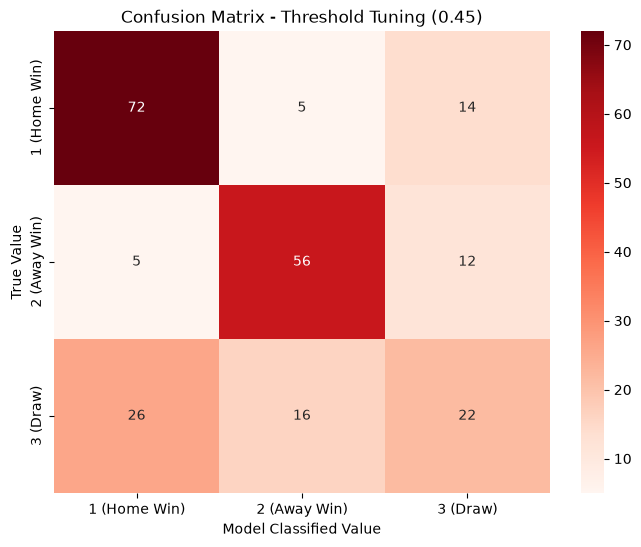

In [5]:
import numpy as np
probabilita = log_reg.predict_proba(X_test_scaled)
classi = log_reg.classes_ 

df_prob = pd.DataFrame(probabilita, columns=[f"Prob_{c}" for c in classi])
df_prob['Risultato_Reale'] = y_test.values

print("\n--- PERCENTAGES OF THE FIRST 5 MATCHES ---")
print((df_prob.head() * 100).round(1)) 


# Apply the manual Threshold
threshold = 0.45
print(f"\n\n\nApply threshold at {threshold * 100:.2f}%")


nuove_previsioni = []
# alter the predictions
for riga in probabilita:
    prob_1 = riga[0] # Probabilità della classe '1'
    prob_2 = riga[1] # Probabilità della classe '2'
    prob_3 = riga[2] # Probabilità della classe '3'
    
    if ((prob_1 > threshold) and (prob_1 > prob_2)):
        nuove_previsioni.append('1')
    elif ((prob_2 > threshold) and (prob_2 > prob_1)):
        nuove_previsioni.append('2')
    else:
        # Se né la squadra di casa né quella in trasferta dominano
        nuove_previsioni.append('3')


nuove_previsioni = np.array(nuove_previsioni)


nuova_accuracy = accuracy_score(y_test, nuove_previsioni)
print(f"\n--- RESULTS WITH THRESHOLD ---")
print(f"Accuracy on Test Set: {nuova_accuracy * 100:.2f}%\n")


# confusion matrix
cm_nuova = confusion_matrix(y_test, nuove_previsioni, labels=['1', '2', '3'])
plt.figure(figsize=(8, 6))
sns.heatmap(cm_nuova, annot=True, fmt='d', cmap='Reds', 
            xticklabels=['1 (Home Win)', '2 (Away Win)', '3 (Draw)'], 
            yticklabels=['1 (Home Win)', '2 (Away Win)', '3 (Draw)'])
plt.title(f"Confusion Matrix - Threshold Tuning ({threshold:.2f})")
plt.xlabel('Model Classified Value')
plt.ylabel('True Value')
plt.show()

The model remains very good in predicting <b>Home Wins (72/91 = 79% accu)</b> or <b>Away Wins (56/73 = 77% accu)</b>, but it behaves slightly better than before when it comes to Draws <b>(22/64 = 34% accu)</b><br>
The overall accuracy is slightly increased from the last best model:
- AutoML Stacked Ensemble: 150/235 = <b>63.8%</b>
- Logistic Regression: 147/228 = <b>64.5%</b>
- Logistic Regression with Threshold Tuning: 150/228 = <b>65.8%</b>

## Random Forest Classifier
Ensemble method based on decision trees, it is very good for small dataset just like this one

In [197]:
from sklearn.ensemble import RandomForestClassifier

### Load and Prepare

#### Load and Split

In [198]:
df = pd.read_excel("trainable_dataset.xlsx", engine='openpyxl', dtype={'Risultato': str})
df['Risultato'] = df['Risultato'].replace('X', '3')
df.columns = df.columns.str.strip()


X = df.drop(columns=['Risultato', 'Home_ID', 'Away_ID']).fillna(0)
y = df['Risultato']



# stratify=y garantisce la stessa proporzione di valori target nei due set
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

#### Standardize Data

In [199]:
# Scaliamo sia test che train
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Train Random Forest Classifier

In [200]:

custom_weights = {
    1: 1.0,
    2: 1.0,
    3: 1.0
}

# training
print("Addestramento della Random Forest in corso...")

# - n_estimators=200: 200 alberi decisionali 
# - max_depth=10: Limitiamo la profondità per evitare overfitting
rf_model = RandomForestClassifier(
    n_estimators=200, 
    max_depth=10, 
    random_state=42, 
    class_weight=custom_weights,
    n_jobs=-1 # Usa tutti i core del processore per fare più in fretta
)

rf_model.fit(X_train_scaled, y_train)

# predict
y_pred_rf = rf_model.predict(X_test_scaled)

Addestramento della Random Forest in corso...


### Random Forest Classifier Results

In [201]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"\n--- RESULTS RANDOM FOREST ---")
print(f"Accuracy on Test Set: {accuracy_rf * 100:.2f}%\n")

print("Detailed Report:")
print(classification_report(y_test, y_pred_rf))


--- RESULTS RANDOM FOREST ---
Accuracy on Test Set: 62.72%

Detailed Report:
              precision    recall  f1-score   support

           1       0.69      0.76      0.72        91
           2       0.67      0.71      0.69        73
           3       0.44      0.34      0.39        64

    accuracy                           0.63       228
   macro avg       0.60      0.60      0.60       228
weighted avg       0.61      0.63      0.62       228



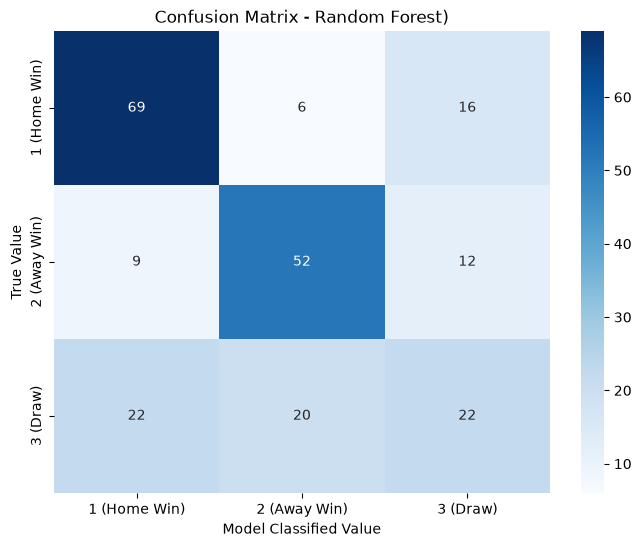

In [202]:
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=['1', '2', '3'])
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues',
            xticklabels=['1 (Home Win)', '2 (Away Win)', '3 (Draw)'], 
            yticklabels=['1 (Home Win)', '2 (Away Win)', '3 (Draw)'])
plt.title(f"Confusion Matrix - Random Forest)")
plt.xlabel('Model Classified Value')
plt.ylabel('True Value')
plt.show()

The Random Forest model is quire good in predicting <b>Home Wins (69/91 = 76% accu)</b> or <b>Away Wins (52/73 = 71% accu)</b>, also it performs just like the altered version of the Logistic Regression when it comes to Draws <b>(22/64 = 34% accu)</b><br>
However, the overall accuracy is worse with respect of all the previous models:
- AutoML Stacked Ensemble: 150/235 = <b>63.8%</b>
- Logistic Regression: 147/228 = <b>64.5%</b>
- Logistic Regression with Threshold Tuning: 150/228 = <b>65.8%</b>
- Random Forest Classifier: 143/228 = <b>62.7%</b>

## Gradient Boosting
They are considered the state of the art of tree based algorythms

In [203]:
from sklearn.ensemble import GradientBoostingClassifier

### Load and Prepare

#### Load and Split

In [204]:
df = pd.read_excel("trainable_dataset.xlsx", engine='openpyxl', dtype={'Risultato': str})
df['Risultato'] = df['Risultato'].replace('X', '3')
df.columns = df.columns.str.strip()


X = df.drop(columns=['Risultato', 'Home_ID', 'Away_ID']).fillna(0)
y = df['Risultato']



# stratify=y garantisce la stessa proporzione di valori target nei due set
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

#### Standardize Data

In [205]:
# Scaliamo sia test che train
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Train Gradient Boosting

In [ ]:
print("Addestramento del Gradient Boosting in corso...")

#Inizializzazione del Gradient Boosting
# - n_estimators=100
# - learning_rate=0.1: Quanto ogni albero influisce sulla correzione degli errori
# - max_depth=3
gb_model = GradientBoostingClassifier(
    n_estimators=100, 
    learning_rate=0.1, 
    max_depth=3, 
    random_state=42
)

# Addestriamo il modello
gb_model.fit(X_train_scaled, y_train)

Addestramento del Gradient Boosting in corso...


,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

### Gradient Boosting Results

In [207]:
y_pred_gb = gb_model.predict(X_test_scaled)

accuracy_gb = accuracy_score(y_test, y_pred_gb)

print(f"\n--- RESULTS GRADIENT BOOSTING ---")
print(f"Accuracy on Test Set: {accuracy_gb * 100:.2f}%\n")

print("Detailed Report:")
print(classification_report(y_test, y_pred_gb))


--- RESULTS GRADIENT BOOSTING ---
Accuracy on Test Set: 64.04%

Detailed Report:
              precision    recall  f1-score   support

           1       0.72      0.74      0.73        91
           2       0.73      0.74      0.73        73
           3       0.41      0.39      0.40        64

    accuracy                           0.64       228
   macro avg       0.62      0.62      0.62       228
weighted avg       0.64      0.64      0.64       228



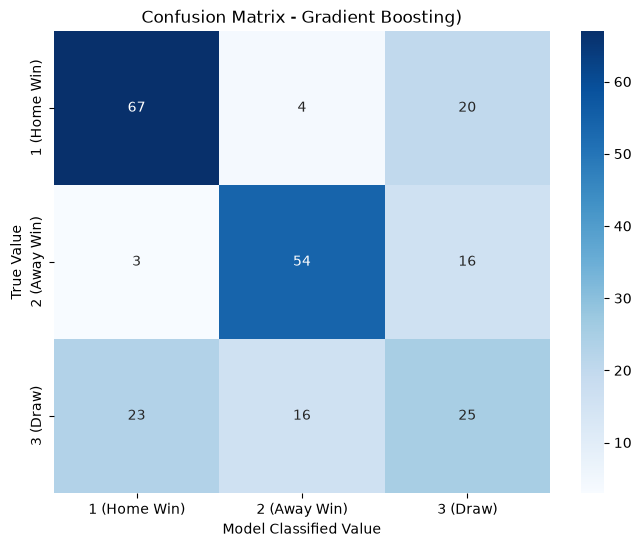

In [208]:
cm_gb = confusion_matrix(y_test, y_pred_gb, labels=['1', '2', '3'])
plt.figure(figsize=(8, 6))
sns.heatmap(cm_gb, annot=True, fmt='d', cmap='Blues',
            xticklabels=['1 (Home Win)', '2 (Away Win)', '3 (Draw)'], 
            yticklabels=['1 (Home Win)', '2 (Away Win)', '3 (Draw)'])
plt.title(f"Confusion Matrix - Gradient Boosting)")
plt.xlabel('Model Classified Value')
plt.ylabel('True Value')
plt.show()

The Gradient Boosting model is performs mediocrely with respect of the other models.<br> 
It is quite good in predicting <b>Home Wins (67/91 = 74% accu)</b> or <b>Away Wins (54/73 = 74% accu)</b>, however it performed better than the other models when it comes to Draws <b>(25/64 = 39% accu)</b><br>
However, the overall accuracy the median of all the tested models:
- AutoML Stacked Ensemble: 150/235 = <b>63.8%</b>
- Logistic Regression: 147/228 = <b>64.5%</b>
- Logistic Regression with Threshold Tuning: 150/228 = <b>65.8%</b>
- Random Forest Classifier: 143/228 = <b>62.7%</b>
- Gradient Boosting: 146/228 = <b>64.04%</b>

### Try to increment accuracy with Threshold Tuning


--- PERCENTAGES OF THE FIRST 5 MATCHES ---
   Prob_1  Prob_2  Prob_3                                    Risultato_Reale
0    91.0     1.8     7.2  1111111111111111111111111111111111111111111111...
1    10.1    40.6    49.4  1111111111111111111111111111111111111111111111...
2    11.0    75.1    13.9  3333333333333333333333333333333333333333333333...
3    25.4    23.7    50.9  1111111111111111111111111111111111111111111111...
4    12.6    61.8    25.5  2222222222222222222222222222222222222222222222...



Apply threshold at 49.00%

--- RESULTS WITH THRESHOLD ---
Accuracy on Test Set: 64.91%



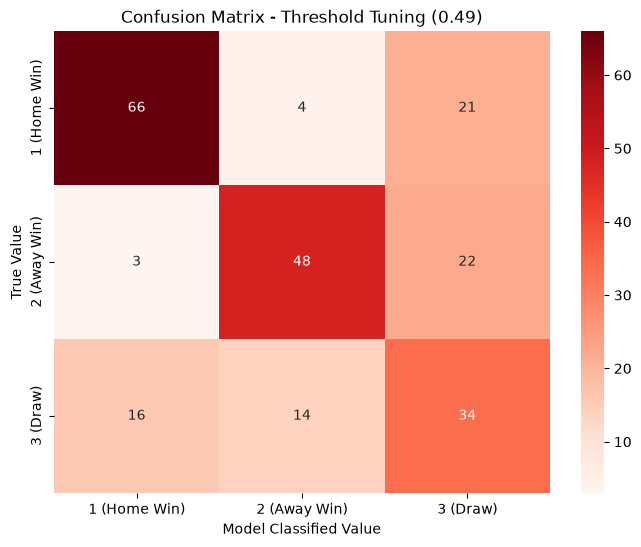

In [ ]:
gb_model2 = GradientBoostingClassifier(
    n_estimators=102, 
    learning_rate=0.1, 
    max_depth=3, 
    random_state=42
)

# Addestriamo il modello
gb_model2.fit(X_train_scaled, y_train)

probabilita = gb_model2.predict_proba(X_test_scaled)
classi = gb_model2.classes_ 

df_prob = pd.DataFrame(probabilita, columns=[f"Prob_{c}" for c in classi])
df_prob['Risultato_Reale'] = y_test.values

print("\n--- PERCENTAGES OF THE FIRST 5 MATCHES ---")
print((df_prob.head() * 100).round(1)) 


# Apply the manual Threshold
threshold = 0.49
print(f"\n\n\nApply threshold at {threshold * 100:.2f}%")


nuove_previsioni = []
# alter the predictions
for riga in probabilita:
    prob_1 = riga[0] # Probabilità della classe '1'
    prob_2 = riga[1] # Probabilità della classe '2'
    prob_3 = riga[2] # Probabilità della classe '3'
    
    if prob_1 > threshold:
        nuove_previsioni.append('1')
    elif prob_2 > threshold:
        nuove_previsioni.append('2')
    else:
        # Se né la squadra di casa né quella in trasferta dominano
        nuove_previsioni.append('3')


nuove_previsioni = np.array(nuove_previsioni)


nuova_accuracy = accuracy_score(y_test, nuove_previsioni)
print(f"\n--- RESULTS WITH THRESHOLD ---")
print(f"Accuracy on Test Set: {nuova_accuracy * 100:.2f}%\n")


# confusion matrix
cm_nuova = confusion_matrix(y_test, nuove_previsioni, labels=['1', '2', '3'])
plt.figure(figsize=(8, 6))
sns.heatmap(cm_nuova, annot=True, fmt='d', cmap='Reds', 
            xticklabels=['1 (Home Win)', '2 (Away Win)', '3 (Draw)'], 
            yticklabels=['1 (Home Win)', '2 (Away Win)', '3 (Draw)'])
plt.title(f"Confusion Matrix - Threshold Tuning ({threshold:.2f})")
plt.xlabel('Model Classified Value')
plt.ylabel('True Value')
plt.show()

The Gradient Boosting model with Threshold Tuning is performs better than the normal one.<br> 
It is quite good in predicting <b>Home Wins (66/91 = 73% accu)</b> but worst in predicting <b>Away Wins (54/73 = 66% accu)</b>, however it is the best performing model when it comes to Draws <b>(34/64 = 53% accu)</b><br>
However, the overall accuracy is not better than the Logistic Regression:
- AutoML Stacked Ensemble: 150/235 = <b>63.8%</b>
- Logistic Regression: 147/228 = <b>64.5%</b>
- Logistic Regression with Threshold Tuning: 150/228 = <b>65.8%</b>
- Random Forest Classifier: 143/228 = <b>62.7%</b>
- Gradient Boosting: 146/228 = <b>64.04%</b>
- Gradient Boosting with Threshold Tuning: 148/228 = <b>64.9%</b>

# Model Training with Delta Stats
Reduce the number of features and increase their usefulness by subtracting feature_Fuori from feature_Casa, obtaining a Delta_feature that might help the model in the learning process

## Create new Dataset with Delta Features

In [210]:
import pandas as pd

df_delta = pd.read_excel("trainable_dataset_delta.xlsx", engine='openpyxl', dtype={'Risultato': str})
df_delta['Risultato'] = df_delta['Risultato'].replace('X', '3')
df_delta.columns = df_delta.columns.str.strip()
df_delta = df_delta.fillna(0)

In [211]:
print("\nCalcolo dei Delta in corso...")

# cerco tutte le colonne che finiscono con "_Casa"
colonne_casa = [col for col in df_delta.columns if col.endswith('_Casa')]

for col_casa in colonne_casa:
    # prendo il nome della statistica
    nome_stat = col_casa.replace('_Casa', '')
    col_fuori = f"{nome_stat}_Fuori"
    
    # Se esiste corrispettivo "_Fuori", sottraggo le var
    if col_fuori in df_delta.columns:
        nome_nuova_colonna = f"Delta_{nome_stat}"
        
        valore_casa = pd.to_numeric(df_delta[col_casa], errors='coerce')
        valore_fuori = pd.to_numeric(df_delta[col_fuori], errors='coerce')
        
        df_delta[nome_nuova_colonna] = valore_casa - valore_fuori


# tenog solo il Target e i Delta
colonne_delta = [col for col in df_delta.columns if col.startswith('Delta_')]


df_finale = df_delta[['Risultato', 'Home_ID', 'Away_ID'] + colonne_delta].copy()

print(f"\nNew dataset has {df_finale.shape[1] - 1} Delta features")
print("\n--- DATASET HEAD ---")
print(df_finale.head())


Calcolo dei Delta in corso...

New dataset has 10 Delta features

--- DATASET HEAD ---
  Risultato  Home_ID  Away_ID  Delta_Ball possession  \
0         2     8534     9876                     -6   
1         2     9891     9875                     -4   
2         2    10233     8535                    -36   
3         1     8636     6504                     -4   
4         3     8686     6480                     20   

   Delta_Expected goals (xG)  Delta_Accurate passes  Delta_Shots inside box  \
0                       0.19                     -7                      -2   
1                      -0.61                     -1                     -10   
2                      -0.78                    -13                      -1   
3                       1.91                      0                       7   
4                       1.76                      9                       7   

   Delta_Shots outside box  Delta_xG open play  Delta_xG set play  \
0                        2     

## Train Best Models

### Logistic Regression without and with Threshold

In [212]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

In [213]:
X = df_finale.drop(columns=['Risultato', 'Home_ID', 'Away_ID']).fillna(0)
y = df_finale['Risultato']



# stratify=y garantisce la stessa proporzione di valori target nei due set
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [214]:
# Scaliamo sia test che train
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [215]:

print("Addestramento della Regressione Logistica in corso...")

log_reg = LogisticRegression(solver='lbfgs', max_iter=1000, random_state=42) # dovrebbe capire da solo che è multiclass
log_reg.fit(X_train_scaled, y_train)


y_pred = log_reg.predict(X_test_scaled)

Addestramento della Regressione Logistica in corso...


In [216]:
accuracy = accuracy_score(y_test, y_pred)
print(f"\n--- LOGISTIC REGRESSION RESULTS ---")
print(f"Test Set Accuracy: {accuracy * 100:.2f}%\n")

print("Detailed Report:")
print(classification_report(y_test, y_pred))


--- LOGISTIC REGRESSION RESULTS ---
Test Set Accuracy: 64.04%

Detailed Report:
              precision    recall  f1-score   support

           1       0.67      0.84      0.74        91
           2       0.70      0.75      0.72        73
           3       0.43      0.23      0.30        64

    accuracy                           0.64       228
   macro avg       0.60      0.61      0.59       228
weighted avg       0.61      0.64      0.61       228



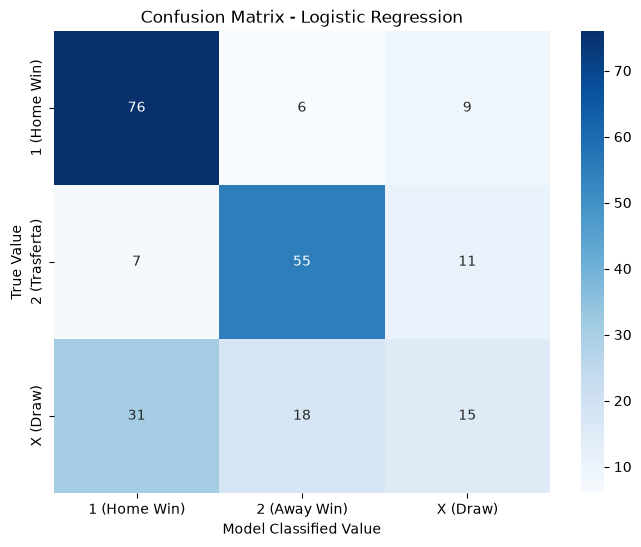

In [217]:

cm = confusion_matrix(y_test, y_pred, labels=['1', '2', '3'])
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['1 (Home Win)', '2 (Away Win)', 'X (Draw)'], 
            yticklabels=['1 (Home Win)', '2 (Trasferta)', 'X (Draw)'])
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Model Classified Value')
plt.ylabel('True Value')
plt.show()


--- PERCENTAGES OF THE FIRST 5 MATCHES ---
   Prob_1  Prob_2  Prob_3                                    Risultato_Reale
0    96.2     0.0     3.7  1111111111111111111111111111111111111111111111...
1     9.6    55.9    34.5  1111111111111111111111111111111111111111111111...
2    52.4     3.9    43.7  3333333333333333333333333333333333333333333333...
3    31.1    27.1    41.8  1111111111111111111111111111111111111111111111...
4    28.2    38.8    33.1  2222222222222222222222222222222222222222222222...



Apply threshold at 46.00%

--- RESULTS WITH THRESHOLD ---
Accuracy on Test Set: 65.79%



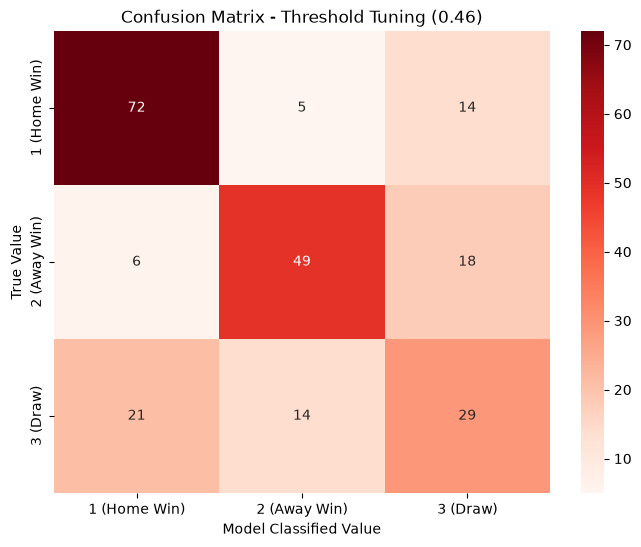

In [ ]:
import numpy as np
probabilita = log_reg.predict_proba(X_test_scaled)
classi = log_reg.classes_ 

df_prob = pd.DataFrame(probabilita, columns=[f"Prob_{c}" for c in classi])
df_prob['Risultato_Reale'] = y_test.values

print("\n--- PERCENTAGES OF THE FIRST 5 MATCHES ---")
print((df_prob.head() * 100).round(1)) 


# Apply the manual Threshold
threshold = 0.46
print(f"\n\n\nApply threshold at {threshold * 100:.2f}%")


nuove_previsioni = []
# alter the predictions
for riga in probabilita:
    prob_1 = riga[0] # Probabilità della classe '1'
    prob_2 = riga[1] # Probabilità della classe '2'
    prob_3 = riga[2] # Probabilità della classe '3'
    
    if prob_1 > threshold:
        nuove_previsioni.append('1')
    elif prob_2 > threshold:
        nuove_previsioni.append('2')
    else:
        # Se né la squadra di casa né quella in trasferta dominano
        nuove_previsioni.append('3')


nuove_previsioni = np.array(nuove_previsioni)


nuova_accuracy = accuracy_score(y_test, nuove_previsioni)
print(f"\n--- RESULTS WITH THRESHOLD ---")
print(f"Accuracy on Test Set: {nuova_accuracy * 100:.2f}%\n")


# confusion matrix
cm_nuova = confusion_matrix(y_test, nuove_previsioni, labels=['1', '2', '3'])
plt.figure(figsize=(8, 6))
sns.heatmap(cm_nuova, annot=True, fmt='d', cmap='Reds', 
            xticklabels=['1 (Home Win)', '2 (Away Win)', '3 (Draw)'], 
            yticklabels=['1 (Home Win)', '2 (Away Win)', '3 (Draw)'])
plt.title(f"Confusion Matrix - Threshold Tuning ({threshold:.2f})")
plt.xlabel('Model Classified Value')
plt.ylabel('True Value')
plt.show()

### Gradient Boosting with and without Threshold Tuning

In [219]:
X = df_finale.drop(columns=['Risultato', 'Home_ID', 'Away_ID']).fillna(0)
y = df_finale['Risultato']



# stratify=y garantisce la stessa proporzione di valori target nei due set
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [220]:
# Scaliamo sia test che train
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
print("Addestramento del Gradient Boosting in corso...")

# inizializzazione del Gradient Boosting
# - n_estimators=100
# - learning_rate=0.1: Quanto ogni albero influisce sulla correzione degli errori
# - max_depth=3
gb_model = GradientBoostingClassifier(
    n_estimators=100, 
    learning_rate=0.1, 
    max_depth=3, 
    random_state=42
)

# Addestriamo il modello
gb_model.fit(X_train_scaled, y_train)

Addestramento del Gradient Boosting in corso...


,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [222]:
y_pred_gb = gb_model.predict(X_test_scaled)

accuracy_gb = accuracy_score(y_test, y_pred_gb)

print(f"\n--- RESULTS GRADIENT BOOSTING ---")
print(f"Accuracy on Test Set: {accuracy_gb * 100:.2f}%\n")

print("Detailed Report:")
print(classification_report(y_test, y_pred_gb))


--- RESULTS GRADIENT BOOSTING ---
Accuracy on Test Set: 63.60%

Detailed Report:
              precision    recall  f1-score   support

           1       0.71      0.79      0.75        91
           2       0.68      0.70      0.69        73
           3       0.43      0.34      0.38        64

    accuracy                           0.64       228
   macro avg       0.61      0.61      0.61       228
weighted avg       0.62      0.64      0.63       228



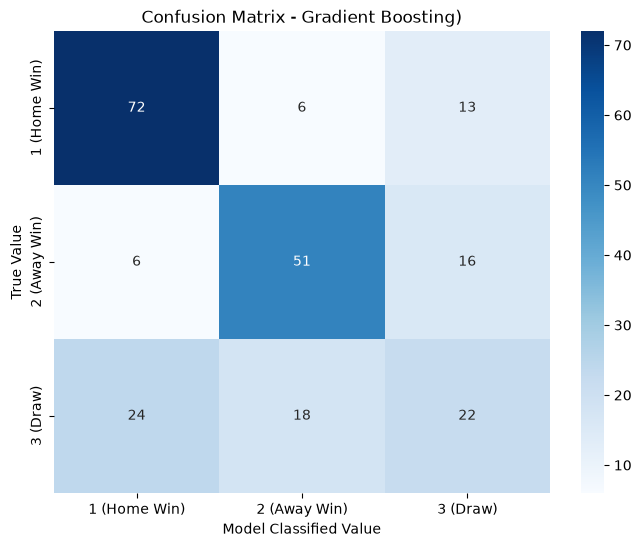

In [223]:
cm_gb = confusion_matrix(y_test, y_pred_gb, labels=['1', '2', '3'])
plt.figure(figsize=(8, 6))
sns.heatmap(cm_gb, annot=True, fmt='d', cmap='Blues',
            xticklabels=['1 (Home Win)', '2 (Away Win)', '3 (Draw)'], 
            yticklabels=['1 (Home Win)', '2 (Away Win)', '3 (Draw)'])
plt.title(f"Confusion Matrix - Gradient Boosting)")
plt.xlabel('Model Classified Value')
plt.ylabel('True Value')
plt.show()


--- PERCENTAGES OF THE FIRST 5 MATCHES ---
   Prob_1  Prob_2  Prob_3                                    Risultato_Reale
0    97.1     0.9     1.9  1111111111111111111111111111111111111111111111...
1    12.4    46.8    40.8  1111111111111111111111111111111111111111111111...
2    36.2     2.5    61.3  3333333333333333333333333333333333333333333333...
3    25.7    24.7    49.5  1111111111111111111111111111111111111111111111...
4    20.4    40.2    39.5  2222222222222222222222222222222222222222222222...



Apply threshold at 50.00%

--- RESULTS WITH THRESHOLD ---
Accuracy on Test Set: 63.16%



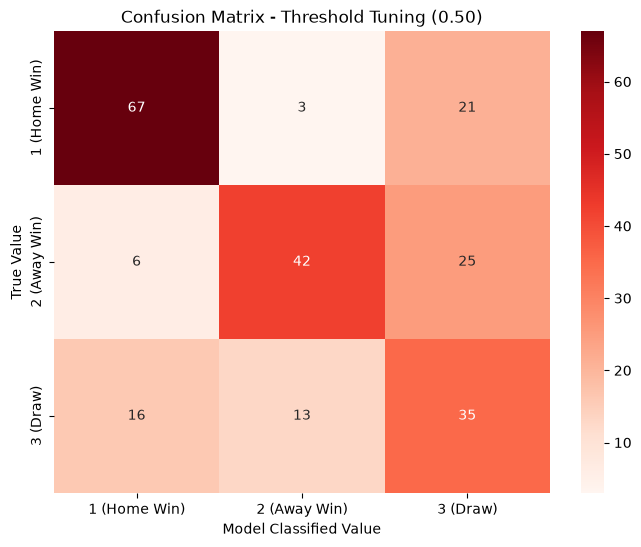

In [ ]:
gb_model2 = GradientBoostingClassifier(
    n_estimators=102, 
    learning_rate=0.1, 
    max_depth=3, 
    random_state=42
)

# Addestriamo il modello
gb_model2.fit(X_train_scaled, y_train)

probabilita = gb_model2.predict_proba(X_test_scaled)
classi = gb_model2.classes_ 

df_prob = pd.DataFrame(probabilita, columns=[f"Prob_{c}" for c in classi])
df_prob['Risultato_Reale'] = y_test.values

print("\n--- PERCENTAGES OF THE FIRST 5 MATCHES ---")
print((df_prob.head() * 100).round(1)) 


# Apply the manual Threshold
threshold = 0.5
print(f"\n\n\nApply threshold at {threshold * 100:.2f}%")


nuove_previsioni = []
# alter the predictions
for riga in probabilita:
    prob_1 = riga[0] # Probabilità della classe '1'
    prob_2 = riga[1] # Probabilità della classe '2'
    prob_3 = riga[2] # Probabilità della classe '3'
    
    if prob_1 > threshold:
        nuove_previsioni.append('1')
    elif prob_2 > threshold:
        nuove_previsioni.append('2')
    else:
        # Se né la squadra di casa né quella in trasferta dominano
        nuove_previsioni.append('3')


nuove_previsioni = np.array(nuove_previsioni)


nuova_accuracy = accuracy_score(y_test, nuove_previsioni)
print(f"\n--- RESULTS WITH THRESHOLD ---")
print(f"Accuracy on Test Set: {nuova_accuracy * 100:.2f}%\n")


# confusion matrix
cm_nuova = confusion_matrix(y_test, nuove_previsioni, labels=['1', '2', '3'])
plt.figure(figsize=(8, 6))
sns.heatmap(cm_nuova, annot=True, fmt='d', cmap='Reds', 
            xticklabels=['1 (Home Win)', '2 (Away Win)', '3 (Draw)'], 
            yticklabels=['1 (Home Win)', '2 (Away Win)', '3 (Draw)'])
plt.title(f"Confusion Matrix - Threshold Tuning ({threshold:.2f})")
plt.xlabel('Model Classified Value')
plt.ylabel('True Value')
plt.show()

### Delta Features Results
The results obtained by using the delta features are consistently worse even if they are not terrible.<br> For that, I will choose as the model for my API the <b>Logistic Regression with Threshold Tuning</b>    